In [61]:
from fastai import *
from fastbook import *

In [2]:
serp_key = "c299e270c9ffdb8c5c8e24b87a9a8032397bdc5c9ea52005b9d84ce2f170e90e"

In [26]:
result = search_images_serpapi("圆头耄耋",engine="google_images", key=serp_key)
ims = result
len(ims)

150

In [ ]:
download_url(ims[1], 'images/maodie2.jpg')
im = Image.open('images/maodie2.jpg')
im.to_thumb(128, 128)

In [3]:
path = Path("cats")
cat_types = "maodie", "cat"

In [8]:
if not path.exists():
    path.mkdir()
dest = (path/"maodie")
dest.mkdir(exist_ok=True)
results = search_images_serpapi("圆头耄耋", key=serp_key, engine="google_images")
download_images(dest, urls=results)

In [4]:
dest = (path/"cat")
dest.mkdir(exist_ok=True)
results = search_images_serpapi("cat", key=serp_key, engine="google_images")
download_images(dest, urls=results)

In [48]:
fns = get_image_files(path)
fns

(#698) [Path('cats/maodie/37926a95-c07f-4839-bfaa-3c49ce1e3f13.png'), Path('cats/maodie/c0f00b8d-aa21-4e72-83f3-c3dacc8e4c8e.jpeg'), Path('cats/maodie/9cb49d93-78e0-4ebe-ae69-9a0de2d1baca.jpeg'), Path('cats/maodie/87a3c0d1-7a1b-4fb5-80fa-f784e3054117.png'), Path('cats/maodie/b5e9f5b2-1d18-4dea-b95e-7d56f5c1d53c.jpg'), Path('cats/maodie/59d22a43-8610-4785-9db5-43a1c2de9cdc.jpg'), Path('cats/maodie/1f50fdfa-72c4-40f2-b7c7-87c5ad3ed626.jpg'), Path('cats/maodie/7d6801a1-7a79-47be-ac2d-8e76a75622db.jpg'), Path('cats/maodie/702d4558-703a-4782-92f7-d06e8d5b9686.jpg'), Path('cats/maodie/d4ea5008-35c1-4fe2-a44c-b7a3190db7e9.jpg'), Path('cats/maodie/a34ea1d6-111b-4d26-b41a-74c9213255d6.jpg'), Path('cats/maodie/ec6a0ae8-4a66-424f-9e5d-973118f823eb.jpg'), Path('cats/maodie/079aab9d-4f23-44df-810f-e7da43bac672.png'), Path('cats/maodie/b2ac493e-7b64-49a8-a2a6-4368b1f4f0e0.jpg'), Path('cats/maodie/b15834e7-3c17-4c43-a8ba-d85f3a54b3d3.jpg'), Path('cats/maodie/30da7855-49bc-4251-b225-53f13e3a5dc0.jpg')

In [49]:
failed=verify_images(fns)
failed

[]

In [50]:
failed.map(Path.unlink);

In [51]:
cats = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(128)
)

In [16]:
dls = cats.dataloaders(path)

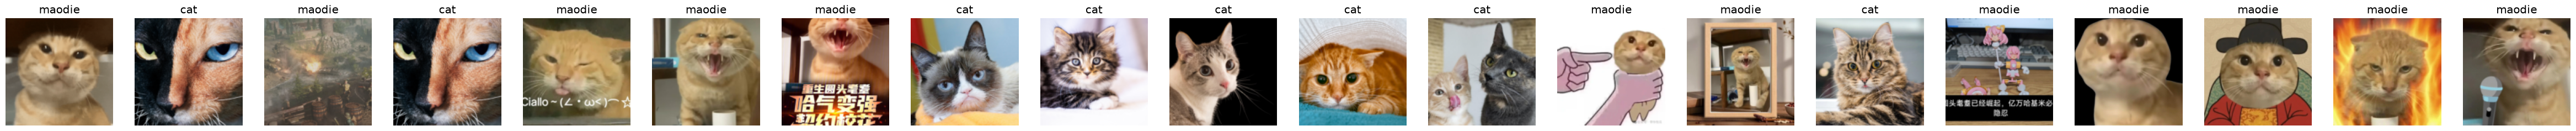

In [22]:
dls.valid.show_batch(max_n=20, nrows=1)

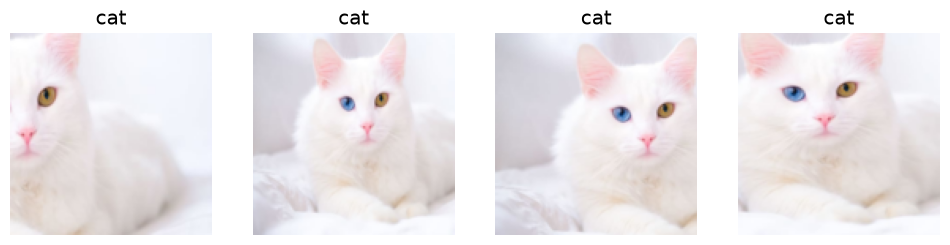

In [33]:
# there are alot different ways to do image transform
cats = cats.new(item_tfms=RandomResizedCrop(128, min_scale=0.3))
dls = cats.dataloaders(path)
dls.train.show_batch(max_n=4, nrows=1, unique=True)

In [53]:
cats = cats.new(
    item_tfms=RandomResizedCrop(224, min_scale=0.5),
    batch_tfms=aug_transforms()
)
dls = cats.dataloaders(path)

In [54]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(4)

epoch,train_loss,valid_loss,error_rate,time
0,0.775282,0.179873,0.043165,00:04


/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch,train_loss,valid_loss,error_rate,time
0,0.209128,0.344071,0.107914,00:04
1,0.138233,0.064608,0.021583,00:04
2,0.093765,0.010342,0.000000,00:04
3,0.068450,0.004582,0.000000,00:04


/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in by

/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/venv/main/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


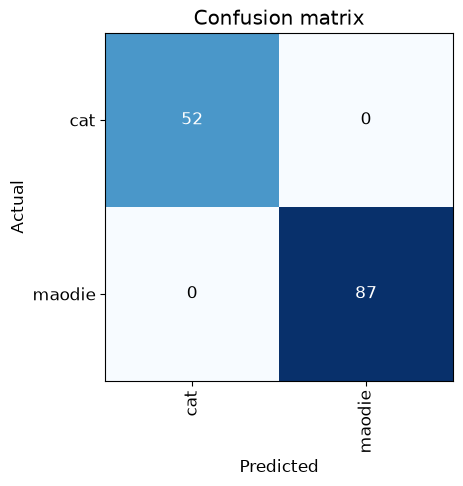

In [65]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

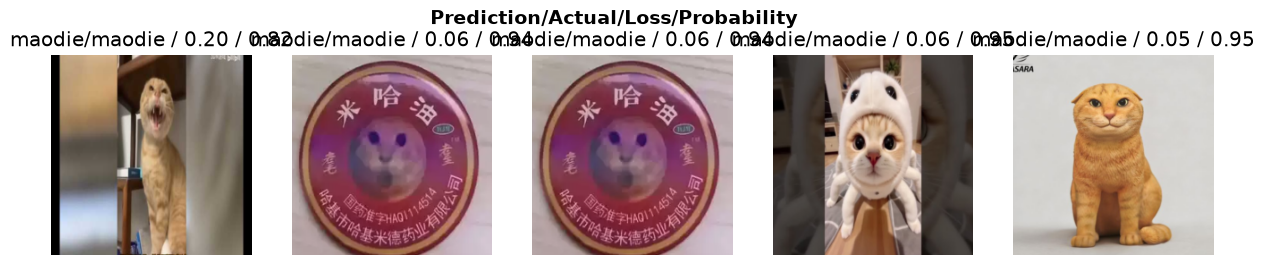

In [59]:
interp.plot_top_losses(5, nrows=1)

In [66]:
cleaner = ImageClassifierCleaner(learn)
cleaner

NameError: name 'ImageClassifierCleaner' is not defined

In [69]:
learn.export(fname='maodie_recognition.pkl')

In [71]:
path = Path()
path.ls(file_exts='.pkl')

[Path('maodie_recognition.pkl')]

In [73]:
learn_inf = load_learner(path/'maodie_recognition.pkl')

In [75]:
learn_inf.predict('images/maodie2.jpg')

('maodie', tensor(1), tensor([0.0062, 0.9938]))

In [77]:
learn_inf.dls.vocab

['cat', 'maodie']

In [80]:
btn_upload = SimpleNamespace(data = ['images/maodie3.jpeg'])

In [86]:
img = PILImage.create(btn_upload.data[-1])

In [87]:
out_pl = widgets.Output()
out_pl.clear_output()
with out_pl: display(image.to_thumb(128,128))
out_pl

Output()

In [88]:
pred,pred_idx,probs=learn_inf.predict(img)

In [ ]:
lbl_pred=widgets.Lable()
lbl_pred.value = f'Prediction: {pred}; Probability: {probs[pred_idx[: